In [ ]:
import glob
import os
import numpy as np
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score

### Define constants

In [23]:
data_dir = './data_bonus/SentenceCorpus/labeled_articles'
valid_labels = {'AIMX', 'OWNX', 'CONT', 'BASE', 'MISC'}
alpha_exponents = list(range(-15, 6))
num_repeats = 10

### Load labeled sentences

In [24]:
sentences = []
labels = []

paths = sorted(glob.glob(os.path.join(data_dir,'**', '*.txt'), recursive= True))
for path in paths:
    with open(path, encoding='utf-8', errors='ignore') as f:
        for line in f:
            line = line.strip()
            if line == '' or line.startswith('###'):
                continue
            parts = line.split(None, 1)
            if len(parts) == 2 and parts[0] in valid_labels:
                labels.append(parts[0])
                sentences.append(parts[1])
y = np.array(labels)
print("files:", len(paths), " sentences:", len(sentences))
print("label counts:", {lab: int((y == lab).sum()) for lab in sorted(valid_labels)})

files: 90  sentences: 3089
label counts: {'AIMX': 190, 'BASE': 61, 'CONT': 168, 'MISC': 1807, 'OWNX': 863}


### Bag of words

In [25]:
vectorizer = CountVectorizer()
X = vectorizer.fit_transform(sentences)
words = vectorizer.get_feature_names_out()
print("X shape:", X.shape)

X shape: (3089, 4010)


### 10 random splits x 21 alphas

In [26]:
accuracies = np.zeros((num_repeats, len(alpha_exponents)))

for seed in range(num_repeats):
    X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.80, random_state=seed)
    for k, exponent in enumerate(alpha_exponents):
        model = MultinomialNB(alpha=2.0**exponent)
        model.fit(X_train, y_train)
        accuracies[seed, k] = accuracy_score(y_test, model.predict(X_test))

mean_acc = accuracies.mean(axis=0)
std_acc = accuracies.std(axis=0)

### plot mean +- std

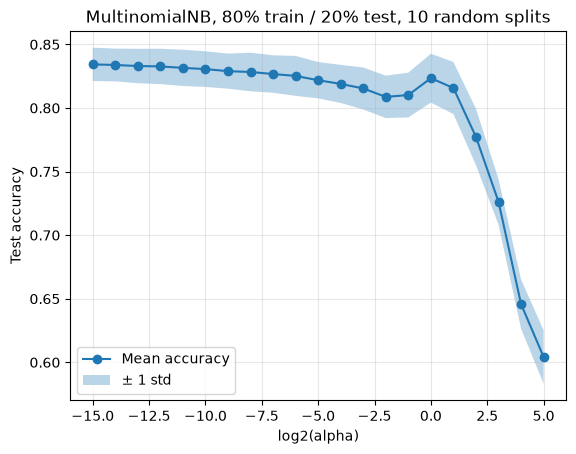

In [27]:
plt.figure()
plt.plot(alpha_exponents, mean_acc, marker='o', label='Mean accuracy')
plt.fill_between(alpha_exponents, mean_acc - std_acc, mean_acc + std_acc,
                 alpha=0.3, label='± 1 std')
plt.xlabel('log2(alpha)')
plt.ylabel('Test accuracy')
plt.title('MultinomialNB, 80% train / 20% test, 10 random splits')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### best alpha and top 5 words per class

In [28]:
best = int(np.argmax(mean_acc))
best_alpha = 2.0 ** alpha_exponents[best]
print("Best alpha: 2^%d = %g  (mean accuracy %.4f, std %.4f)" % (alpha_exponents[best], best_alpha, mean_acc[best], std_acc[best]))

# Train at the best alpha on the seed-0 training split
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.80, random_state=0)
model = MultinomialNB(alpha=best_alpha)
model.fit(X_train, y_train)

for class_index, class_name in enumerate(model.classes_):
    log_probs = model.feature_log_prob_[class_index]
    top5 = np.argsort(log_probs)[::-1][:5]
    print(class_name)
    for word_index in top5:
        print(" %-12s P(word | class) = %.4f" % (words[word_index], np.exp(log_probs[word_index])))

Best alpha: 2^-15 = 3.05176e-05  (mean accuracy 0.8343, std 0.0131)
AIMX
 the          P(word | class) = 0.0596
 of           P(word | class) = 0.0431
 to           P(word | class) = 0.0296
 we           P(word | class) = 0.0250
 and          P(word | class) = 0.0242
BASE
 the          P(word | class) = 0.0430
 of           P(word | class) = 0.0378
 and          P(word | class) = 0.0378
 citation     P(word | class) = 0.0304
 in           P(word | class) = 0.0267
CONT
 the          P(word | class) = 0.0423
 of           P(word | class) = 0.0420
 and          P(word | class) = 0.0254
 to           P(word | class) = 0.0251
 in           P(word | class) = 0.0214
MISC
 the          P(word | class) = 0.0599
 of           P(word | class) = 0.0423
 to           P(word | class) = 0.0290
 citation     P(word | class) = 0.0248
 and          P(word | class) = 0.0243
OWNX
 the          P(word | class) = 0.0588
 of           P(word | class) = 0.0390
 and          P(word | class) = 0.0266
 to       

### Results
- The best alpha by mean accuracy is 2^-15, with mean accuracy 0.834 and std 0.013 over 10 random splits.
- Accuracy decreases as alpha grows, with a small bump around alpha = 2^0, and drops to about 0.60 at alpha = 2^5. That is close to always predicting the majority class. MISC is 1807 of 3089 sentences, or 58.5%. Large alpha flattens the word probabilities toward uniform, so the class prior dominates.
- The five highest-probability words per class (at alpha = 2^-15, seed-0 training split):

| Class | Top 5 words |
|---|---|
| AIMX | the, of, to, we, and |
| BASE | the, of, and, citation, in |
| CONT | the, of, and, to, in |
| MISC | the, of, to, citation, and |
| OWNX | the, of, and, to, in |

- The top words are mostly stop words ("the", "of", "to", "and", "in"), which are frequent in every class, so they are not informative. The few class-specific ones are "we" for AIMX (authors stating their own aim) and "citation" for BASE and MISC (references to other work).